In [2]:
import pandas as pd

path = "/content/Sales Transaction v.4a.csv"
df = pd.read_csv(path)
df.head()


,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country
0,581482,12/9/2019,22485,Set Of 2 Wooden Market Crates,21.47,12,17490.0,United Kingdom
1,581475,12/9/2019,22596,Christmas Star Wish List Chalkboard,10.65,36,13069.0,United Kingdom
2,581475,12/9/2019,23235,Storage Tin Vintage Leaf,11.53,12,13069.0,United Kingdom
3,581475,12/9/2019,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069.0,United Kingdom
4,581475,12/9/2019,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069.0,United Kingdom


In [3]:
df.shape


(536350, 8)

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536350 entries, 0 to 536349
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionNo  536350 non-null  object 
 1   Date           536350 non-null  object 
 2   ProductNo      536350 non-null  object 
 3   ProductName    536350 non-null  object 
 4   Price          536350 non-null  float64
 5   Quantity       536350 non-null  int64  
 6   CustomerNo     536295 non-null  float64
 7   Country        536350 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.7+ MB


In [5]:
df.isna().sum()


,0
TransactionNo,0
Date,0
ProductNo,0
ProductName,0
Price,0
Quantity,0
CustomerNo,55
Country,0


In [6]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')


In [7]:
(df['Quantity'] < 0).sum()


np.int64(8585)

In [8]:
df['TotalValue'] = df['Price'] * df['Quantity']

df_sales = df[df['Quantity'] > 0].copy()


In [10]:
df_sales['Year'] = df_sales['Date'].dt.year
df_sales['Month'] = df_sales['Date'].dt.month
df_sales['YearMonth'] = df_sales['Date'].dt.to_period('M')


In [11]:
monthly_sales = (
    df_sales
    .groupby('YearMonth')['TotalValue']
    .sum()
    .reset_index()
)

monthly_sales.head()


,YearMonth,TotalValue
0,2018-12,4415415.52
1,2019-01,4559856.37
2,2019-02,3335017.18
3,2019-03,4398401.60
4,2019-04,3589497.88


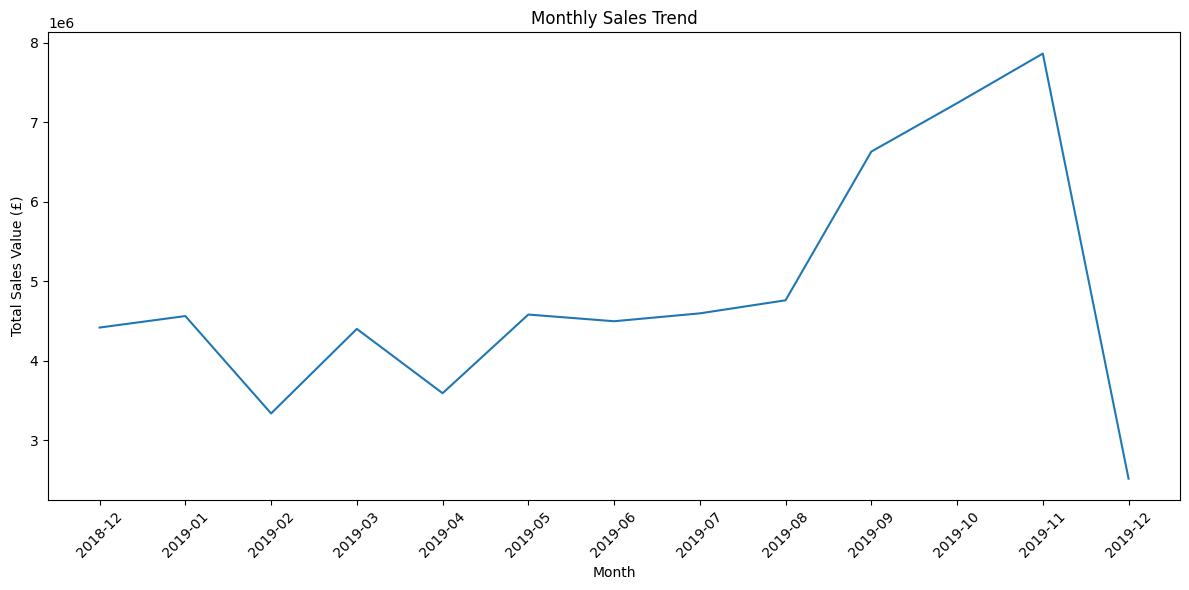

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(monthly_sales['YearMonth'].astype(str),
         monthly_sales['TotalValue'])
plt.xticks(rotation=45)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Value (£)")
plt.tight_layout()
plt.show()


In [13]:
monthly_sales.to_csv("monthly_sales.csv", index=False)


In [14]:
top_products = (
    df_sales
    .groupby('ProductName')['TotalValue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products


,ProductName,TotalValue
0,Paper Craft Little Birdie,1002718.10
1,Medium Ceramic Top Storage Jar,881990.18
2,Popcorn Holder,587433.94
3,World War 2 Gliders Asstd Designs,569735.39
4,Cream Hanging Heart T-Light Holder,484592.69
5,Assorted Colour Bird Ornament,421318.74
6,Pack Of 72 Retrospot Cake Cases,391485.03
7,Rabbit Night Light,329029.89
8,Regency Cakestand 3 Tier,307483.85
9,Jumbo Bag Red Retrospot,297205.04


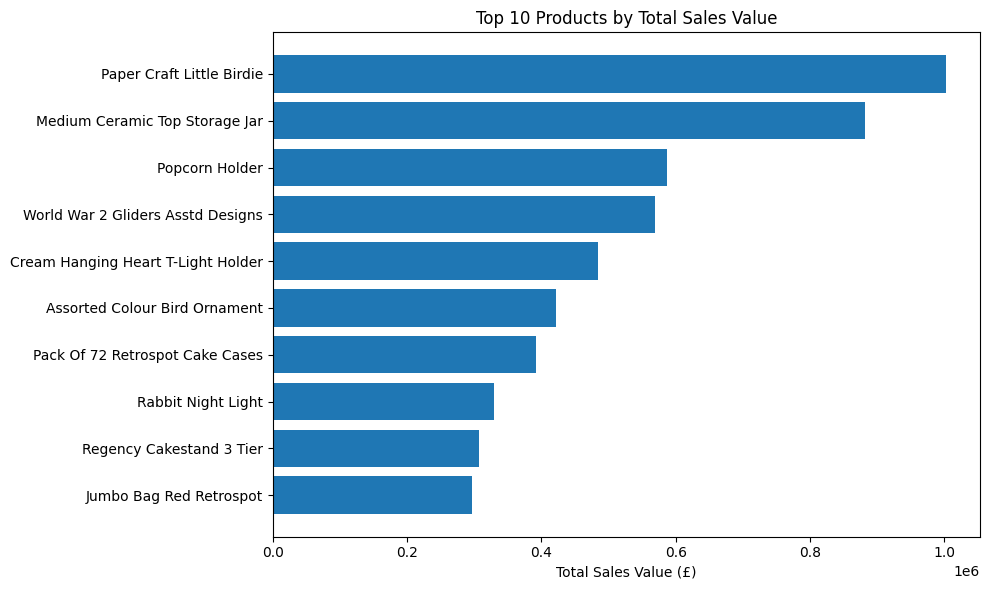

In [15]:
plt.figure(figsize=(10,6))
plt.barh(top_products['ProductName'],
         top_products['TotalValue'])
plt.gca().invert_yaxis()
plt.title("Top 10 Products by Total Sales Value")
plt.xlabel("Total Sales Value (£)")
plt.tight_layout()
plt.show()


In [16]:
top_products.to_csv("top_products.csv", index=False)


In [17]:
top_customers = (
    df_sales
    .groupby('CustomerNo')['TotalValue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_customers


,CustomerNo,TotalValue
0,14646.0,2112282.03
1,16446.0,1002741.57
2,14911.0,914633.52
3,12415.0,900545.54
4,18102.0,897137.36
5,17450.0,891438.53
6,12346.0,840113.80
7,14156.0,694965.02
8,13694.0,646116.78
9,17511.0,639006.19


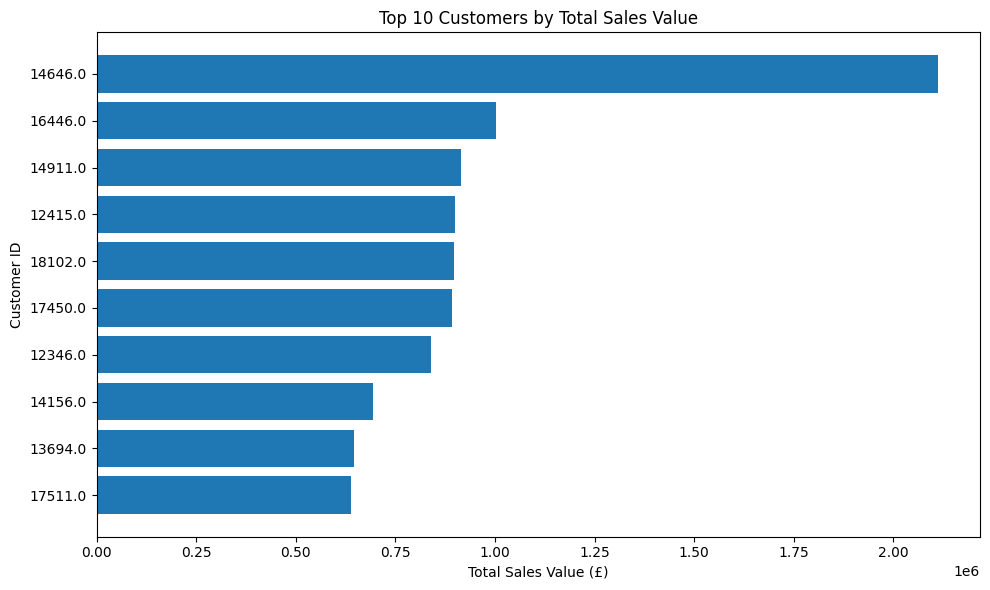

In [18]:
plt.figure(figsize=(10,6))
plt.barh(top_customers['CustomerNo'].astype(str),
         top_customers['TotalValue'])
plt.gca().invert_yaxis()
plt.title("Top 10 Customers by Total Sales Value")
plt.xlabel("Total Sales Value (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


In [19]:
country_sales = (
    df_sales.groupby('Country')['TotalValue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales


,TotalValue
Country,
United Kingdom,52524658.47
Netherlands,2151553.59
EIRE,1713410.95
Germany,1371543.27
France,1330652.89
Australia,995607.91
Sweden,401879.89
Switzerland,361969.25
Japan,293155.44


In [20]:
basket_value = (
    df_sales.groupby('TransactionNo')['TotalValue']
    .sum()
)

basket_value.describe()


,TotalValue
count,1.979000e+04
mean,3.181707e+03
std,1.126961e+04
min,5.460000e+00
25%,8.301600e+02
50%,1.717000e+03
75%,3.312035e+03
max,1.002718e+06


In [21]:
customer_freq = (
    df_sales.groupby('CustomerNo')['TransactionNo']
    .nunique()
)


In [22]:
customer_freq.head(10)


,TransactionNo
CustomerNo,
12004.0,1
12006.0,1
12008.0,1
12013.0,1
12024.0,1
12025.0,1
12026.0,1
12031.0,1
12042.0,1


In [23]:
customer_freq.describe()


,TransactionNo
count,4718.000000
mean,4.194362
std,7.396101
min,1.000000
25%,1.000000
50%,2.000000
75%,5.000000
max,207.000000


In [24]:
customer_freq.value_counts().head(10)


,count
TransactionNo,
1,1577
2,941
3,579
4,433
5,253
6,196
7,154
8,106
9,74


In [25]:
customer_freq_df = customer_freq.reset_index()
customer_freq_df.columns = ['CustomerNo', 'TransactionCount']

customer_freq_df.head()


,CustomerNo,TransactionCount
0,12004.0,1
1,12006.0,1
2,12008.0,1
3,12013.0,1
4,12024.0,1


In [26]:
customer_freq.head(10)
customer_freq.describe()
customer_freq.value_counts().head(10)


,count
TransactionNo,
1,1577
2,941
3,579
4,433
5,253
6,196
7,154
8,106
9,74


In [31]:
customer_freq_df = (
    customer_freq
    .reset_index()
    .rename(columns={'TransactionNo': 'TransactionCount'})
)

customer_freq_df.head()


,CustomerNo,TransactionCount
0,12004.0,1
1,12006.0,1
2,12008.0,1
3,12013.0,1
4,12024.0,1


In [32]:
customer_freq.describe()


,TransactionNo
count,4718.000000
mean,4.194362
std,7.396101
min,1.000000
25%,1.000000
50%,2.000000
75%,5.000000
max,207.000000


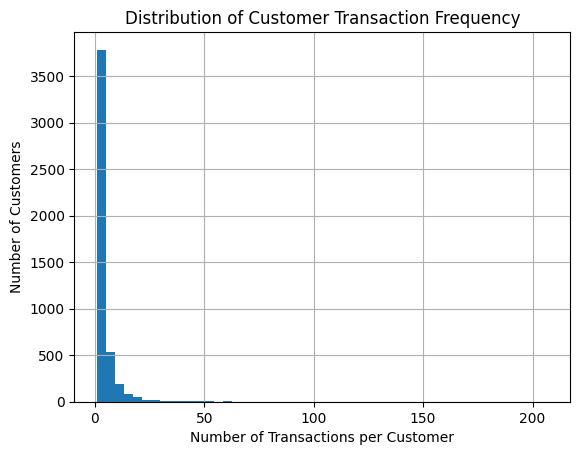

In [33]:
import matplotlib.pyplot as plt

customer_freq.hist(bins=50)
plt.title("Distribution of Customer Transaction Frequency")
plt.xlabel("Number of Transactions per Customer")
plt.ylabel("Number of Customers")
plt.show()


In [34]:
customer_summary = (
    df_sales
    .groupby('CustomerNo')
    .agg(
        TransactionCount=('TransactionNo', 'nunique'),
        TotalRevenue=('TotalValue', 'sum')
    )
    .reset_index()
)

customer_summary.head()


,CustomerNo,TransactionCount,TotalRevenue
0,12004.0,1,1509.60
1,12006.0,1,24.76
2,12008.0,1,5689.57
3,12013.0,1,69.96
4,12024.0,1,149.52


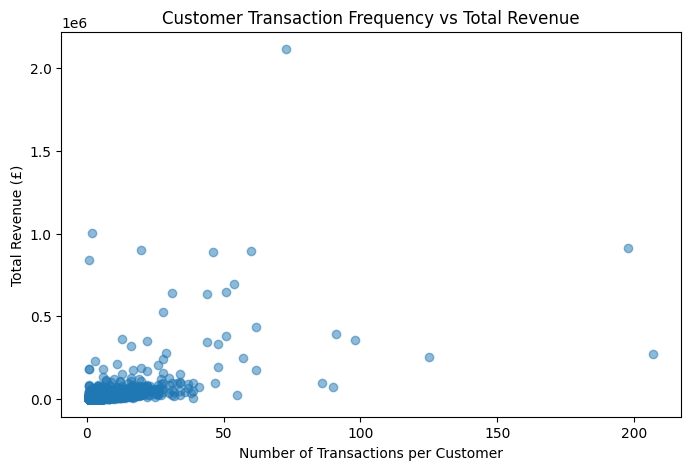

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(
    customer_summary['TransactionCount'],
    customer_summary['TotalRevenue'],
    alpha=0.5
)
plt.xlabel("Number of Transactions per Customer")
plt.ylabel("Total Revenue (£)")
plt.title("Customer Transaction Frequency vs Total Revenue")
plt.show()


In [36]:
customer_summary['RevenueRank'] = customer_summary['TotalRevenue'].rank(pct=True)


In [38]:
top_10 = customer_summary[customer_summary['RevenueRank'] >= 0.90]

top_10_share = top_10['TotalRevenue'].sum() / customer_summary['TotalRevenue'].sum()

top_10_share


np.float64(0.5896571483417811)

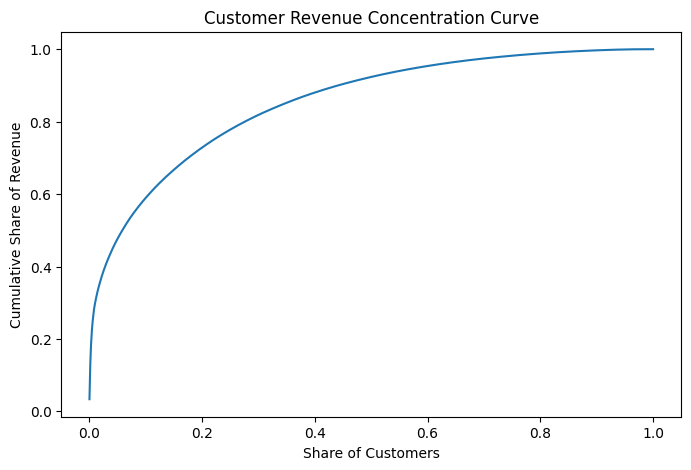

In [40]:
import numpy as np

customer_sorted = customer_summary.sort_values('TotalRevenue', ascending=False).copy()

customer_sorted['CumulativeRevenue'] = customer_sorted['TotalRevenue'].cumsum()
customer_sorted['CumulativeRevenueShare'] = (
    customer_sorted['CumulativeRevenue'] / customer_sorted['TotalRevenue'].sum()
)

customer_sorted['CustomerShare'] = np.arange(1, len(customer_sorted) + 1) / len(customer_sorted)

plt.figure(figsize=(8,5))
plt.plot(customer_sorted['CustomerShare'], customer_sorted['CumulativeRevenueShare'])
plt.xlabel("Share of Customers")
plt.ylabel("Cumulative Share of Revenue")
plt.title("Customer Revenue Concentration Curve")
plt.show()


In [41]:
# Customer-level aggregation
customer_summary = (
    df_sales
    .groupby('CustomerNo')
    .agg(
        TotalRevenue=('TotalValue', 'sum'),
        TransactionCount=('TransactionNo', 'nunique'),
        AverageBasket=('TotalValue', 'mean')
    )
    .reset_index()
)

customer_summary.head()


,CustomerNo,TotalRevenue,TransactionCount,AverageBasket
0,12004.0,1509.60,1,26.957143
1,12006.0,24.76,1,24.760000
2,12008.0,5689.57,1,28.027438
3,12013.0,69.96,1,69.960000
4,12024.0,149.52,1,29.904000


In [43]:
customer_summary.describe()


,CustomerNo,TotalRevenue,TransactionCount,AverageBasket
count,4718.000000,4.718000e+03,4718.000000,4718.000000
mean,15245.855235,1.334589e+04,4.194362,471.716875
std,1741.805611,5.439743e+04,7.396101,13246.086964
min,12004.000000,5.970000e+00,1.000000,5.970000
25%,13742.250000,1.838447e+03,1.000000,49.536951
50%,15249.500000,4.828470e+03,2.000000,101.248289
75%,16746.750000,1.190628e+04,5.000000,150.808220
max,18287.000000,2.112282e+06,207.000000,840113.800000


In [45]:
# Revenue thresholds
q25 = customer_summary['TotalRevenue'].quantile(0.25)
q75 = customer_summary['TotalRevenue'].quantile(0.75)

def segment_customer(revenue):
    if revenue <= q25:
        return 'Low Value'
    elif revenue <= q75:
        return 'Medium Value'
    else:
        return 'High Value'

customer_summary['RevenueSegment'] = customer_summary['TotalRevenue'].apply(segment_customer)

customer_summary['RevenueSegment'].value_counts()


,count
RevenueSegment,
Medium Value,2358
Low Value,1180
High Value,1180


In [46]:
segment_summary = (
    customer_summary
    .groupby('RevenueSegment')
    .agg(
        Customers=('CustomerNo', 'count'),
        AvgRevenue=('TotalRevenue', 'mean'),
        AvgTransactions=('TransactionCount', 'mean')
    )
    .reset_index()
)

segment_summary


,RevenueSegment,Customers,AvgRevenue,AvgTransactions
0,High Value,1180,41524.421593,9.750000
1,Low Value,1180,952.804788,1.361864
2,Medium Value,2358,5446.465314,2.831637


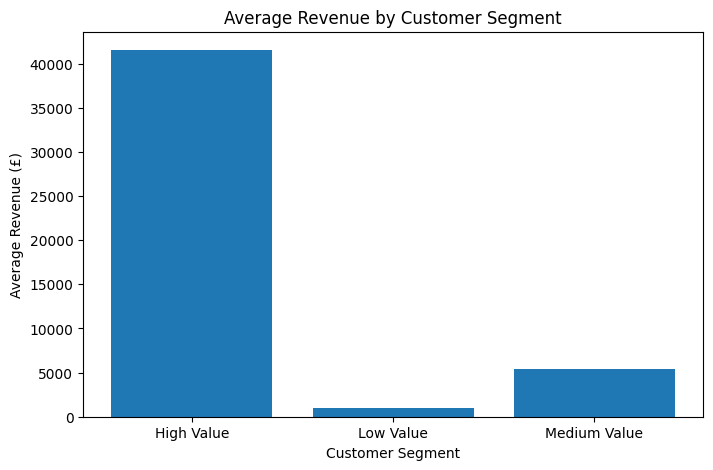

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(segment_summary['RevenueSegment'], segment_summary['AvgRevenue'])
plt.title('Average Revenue by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Revenue (£)')
plt.show()


In [48]:
monthly_sales = (
    df_sales
    .set_index('Date')
    .resample('M')['TotalValue']
    .sum()
    .reset_index()
)

monthly_sales.to_csv('monthly_sales.csv', index=False)


/tmp/ipython-input-3749413476.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample('M')['TotalValue']


In [49]:
product_sales = (
    df_sales
    .groupby('ProductName')['TotalValue']
    .sum()
    .reset_index()
    .sort_values('TotalValue', ascending=False)
)

product_sales.to_csv('product_sales.csv', index=False)


In [50]:
customer_summary = (
    df_sales
    .groupby('CustomerNo')
    .agg(
        TotalRevenue=('TotalValue', 'sum'),
        Transactions=('TransactionNo', 'nunique')
    )
    .reset_index()
)

customer_summary.to_csv('customer_summary.csv', index=False)


In [51]:
country_sales = (
    df_sales
    .groupby('Country')['TotalValue']
    .sum()
    .reset_index()
)

country_sales.to_csv('country_sales.csv', index=False)
